# IMAES Experiment 5 - Backward Chaining Engine with Askable Facts

## Aim

To implement a backward chaining engine which performs goal-driven reasoning for car-fault diagnosis using askable facts.

## Objectives

- Implement backward chaining for car-fault diagnosis.
- Represent diagnostic knowledge using IF-THEN production rules.
- Distinguish known facts, askable facts, and derived facts.
- Ask only for facts required by the current hypothesis.
- Add a starter motor fault using clicking sound and engine not cranking.
- Study the effect of changing hypothesis order.
- Add a WHY option to explain the rule responsible for a question.


## Theory

Backward chaining is a goal-driven inference method. The engine starts with a hypothesis and works backward to determine whether the conditions needed to establish that hypothesis are true.

For a rule of the form:

**IF condition1 AND condition2 THEN conclusion**

the engine tries to prove the conclusion by recursively proving its conditions.

If a required condition is not already known and is askable, the engine asks for that fact and stores the answer in working memory. The stored answer can then be reused during the diagnosis.

The process continues until a hypothesis is proved, a required condition fails, or no rule can establish the hypothesis.

The order of hypotheses affects the questions asked because the engine explores hypotheses in the given order.


## Algorithm

1. Initialize the rule base.
2. Initialize working memory.
3. Select a fault hypothesis.
4. Check whether the goal is already known.
5. Find rules whose conclusion matches the goal.
6. Recursively prove each condition of the selected rule.
7. If an unknown condition is askable, ask the user for its value.
8. Store the answer in working memory.
9. If all conditions are true, derive the goal.
10. If a condition fails, try another rule when available.
11. Continue until a diagnosis is obtained or all hypotheses fail.
12. When WHY is selected, display the rule responsible for requesting the current fact.


## Knowledge Base

The diagnostic system contains the following faults:

- battery fault
- starter motor fault
- fuel system fault
- ignition fault
- electrical fault
- engine overheating

The required starter motor rule is:

**IF clicking sound AND engine not cranking THEN starter motor fault**


In [1]:
from dataclasses import dataclass
from typing import List, Dict, Optional, Tuple
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


In [2]:
@dataclass(frozen=True)
class Rule:
    rule_id: str
    conditions: Tuple[str, ...]
    conclusion: str
    description: str = ""

    def __str__(self):
        return (
            f"{self.rule_id}: IF "
            + " AND ".join(self.conditions)
            + f" THEN {self.conclusion}"
        )


In [3]:
# Car-fault diagnostic knowledge base

rules = [
    Rule(
        "R1",
        ("headlights_dim", "engine_not_cranking"),
        "battery_fault",
        "Dim headlights and an engine that does not crank indicate a battery fault."
    ),
    Rule(
        "R2",
        ("clicking_sound", "engine_not_cranking"),
        "starter_motor_fault",
        "A clicking sound with an engine that does not crank indicates a starter motor fault."
    ),
    Rule(
        "R3",
        ("fuel_available", "fuel_pump_sound", "engine_cranks"),
        "fuel_system_fault",
        "Fuel-related symptoms with a cranking engine indicate a fuel-system fault."
    ),
    Rule(
        "R4",
        ("fuel_available", "engine_cranks", "spark_present"),
        "ignition_fault",
        "Fuel and cranking information together with ignition observations indicate an ignition fault."
    ),
    Rule(
        "R5",
        ("battery_voltage_low", "engine_not_cranking"),
        "electrical_fault",
        "Low battery voltage with a non-cranking engine indicates an electrical fault."
    ),
    Rule(
        "R6",
        ("temperature_high", "coolant_low"),
        "engine_overheating",
        "High temperature with low coolant indicates engine overheating."
    )
]

rule_table = pd.DataFrame([
    {
        "Rule": r.rule_id,
        "Conditions": " AND ".join(r.conditions),
        "Conclusion": r.conclusion,
        "Description": r.description
    }
    for r in rules
])

display(rule_table)


,Rule,Conditions,Conclusion,Description
0,R1,headlights_dim AND engine_not_cranking,battery_fault,Dim headlights and an engine that does not cra...
1,R2,clicking_sound AND engine_not_cranking,starter_motor_fault,A clicking sound with an engine that does not ...
2,R3,fuel_available AND fuel_pump_sound AND engine_...,fuel_system_fault,Fuel-related symptoms with a cranking engine i...
3,R4,fuel_available AND engine_cranks AND spark_pre...,ignition_fault,Fuel and cranking information together with ig...
4,R5,battery_voltage_low AND engine_not_cranking,electrical_fault,Low battery voltage with a non-cranking engine...
5,R6,temperature_high AND coolant_low,engine_overheating,High temperature with low coolant indicates en...


## Backward Chaining Engine

The implementation supports recursive reasoning, askable facts, hypothesis ordering, question tracing, and WHY explanations.


In [4]:
class BackwardChainingEngine:
    def __init__(
        self,
        rules: List[Rule],
        askable_facts: List[str],
        initial_facts: Optional[Dict[str, bool]] = None,
        interactive: bool = False,
        scripted_answers: Optional[Dict[str, bool]] = None,
        why_mode: bool = False
    ):
        self.rules = rules
        self.askable = set(askable_facts)
        self.facts = dict(initial_facts or {})
        self.interactive = interactive
        self.scripted_answers = dict(scripted_answers or {})
        self.why_mode = why_mode
        self.question_log = []
        self.reason_log = []
        self.proof_log = []
        self.asked_facts = set()

    def rules_for(self, goal):
        return [r for r in self.rules if r.conclusion == goal]

    def ask_fact(self, fact, rule=None, goal=None):
        if fact in self.facts:
            return self.facts[fact]

        if self.interactive:
            while True:
                answer = input(f"Is '{fact}' true? [y/n/why]: ").strip().lower()

                if answer == "why":
                    if rule:
                        print(f"WHY: {rule}")
                        print(f"Reason: {rule.description}")
                    else:
                        print(f"WHY: '{fact}' is needed to establish '{goal}'.")
                    continue

                if answer in {"y", "yes"}:
                    value = True
                    break

                if answer in {"n", "no"}:
                    value = False
                    break

                print("Please enter y, n, or why.")
        else:
            value = bool(self.scripted_answers.get(fact, False))

        self.facts[fact] = value
        self.asked_facts.add(fact)

        self.question_log.append({
            "fact": fact,
            "value": value,
            "goal": goal,
            "rule": rule.rule_id if rule else None
        })

        if self.why_mode:
            self.reason_log.append({
                "fact": fact,
                "goal": goal,
                "rule": rule.rule_id if rule else None,
                "reason": (
                    f"{rule.rule_id}: IF {' AND '.join(rule.conditions)} "
                    f"THEN {rule.conclusion}"
                    if rule else
                    f"The fact is required while proving {goal}."
                )
            })

        return value

    def prove(self, goal, stack=None, parent_rule=None):
        stack = list(stack or [])

        if goal in self.facts:
            value = bool(self.facts[goal])
            self.proof_log.append((goal, value, "known"))
            return value

        if goal in stack:
            self.proof_log.append((goal, False, "cycle"))
            return False

        candidate_rules = self.rules_for(goal)

        if not candidate_rules:
            if goal in self.askable:
                value = self.ask_fact(goal, parent_rule, goal)
                self.proof_log.append((goal, value, "asked"))
                return value

            self.facts[goal] = False
            self.proof_log.append((goal, False, "no_rule"))
            return False

        for rule in candidate_rules:
            all_true = True

            for condition in rule.conditions:
                if not self.prove(condition, stack + [goal], rule):
                    all_true = False
                    break

            if all_true:
                self.facts[goal] = True
                self.proof_log.append((goal, True, rule.rule_id))
                return True

        self.facts[goal] = False
        self.proof_log.append((goal, False, "rules_failed"))
        return False

    def diagnose(self, hypotheses):
        for hypothesis in hypotheses:
            if self.prove(hypothesis):
                return {
                    "fault": hypothesis,
                    "success": True,
                    "facts": dict(self.facts),
                    "questions": list(self.question_log),
                    "proof": list(self.proof_log),
                    "reasons": list(self.reason_log)
                }

        return {
            "fault": None,
            "success": False,
            "facts": dict(self.facts),
            "questions": list(self.question_log),
            "proof": list(self.proof_log),
            "reasons": list(self.reason_log)
        }


In [5]:
askable_facts = [
    "headlights_dim",
    "engine_cranks",
    "engine_not_cranking",
    "clicking_sound",
    "fuel_available",
    "fuel_pump_sound",
    "spark_present",
    "engine_stalls",
    "battery_voltage_low",
    "temperature_high",
    "coolant_low"
]

hypotheses = [
    "battery_fault",
    "starter_motor_fault",
    "fuel_system_fault",
    "ignition_fault",
    "electrical_fault",
    "engine_overheating"
]

print("Askable facts:")
for fact in askable_facts:
    print("-", fact)

print("\nHypotheses:")
for hypothesis in hypotheses:
    print("-", hypothesis)


Askable facts:
- headlights_dim
- engine_cranks
- engine_not_cranking
- clicking_sound
- fuel_available
- fuel_pump_sound
- spark_present
- engine_stalls
- battery_voltage_low
- temperature_high
- coolant_low

Hypotheses:
- battery_fault
- starter_motor_fault
- fuel_system_fault
- ignition_fault
- electrical_fault
- engine_overheating


# Demonstration

A vehicle is described by a clicking sound and an engine that does not crank. The engine should identify the starter motor fault.


In [6]:
starter_answers = {
    "headlights_dim": False,
    "engine_not_cranking": True,
    "clicking_sound": True
}

engine = BackwardChainingEngine(
    rules=rules,
    askable_facts=askable_facts,
    scripted_answers=starter_answers
)

result = engine.diagnose(hypotheses)

print("Diagnosis:", result["fault"])
print("Successful diagnosis:", result["success"])
print("Facts asked:", [q["fact"] for q in result["questions"]])


Diagnosis: starter_motor_fault
Successful diagnosis: True
Facts asked: ['headlights_dim', 'clicking_sound', 'engine_not_cranking']


In [7]:
# Reasoning trace
trace = pd.DataFrame(result["proof"], columns=["Goal", "Result", "Reason"])
display(trace)


,Goal,Result,Reason
0,headlights_dim,False,asked
1,battery_fault,False,rules_failed
2,clicking_sound,True,asked
3,engine_not_cranking,True,asked
4,starter_motor_fault,True,R2


# Exercise 1 - Starter Motor Fault

Add a starter motor fault using clicking sound and engine not cranking.

Observe:

- which facts are asked,
- whether the correct fault is identified.


In [8]:
exercise1_table = pd.DataFrame(result["questions"])
display(exercise1_table)

print("Identified fault:", result["fault"])
print("Correct starter motor diagnosis:", result["fault"] == "starter_motor_fault")
print("Facts asked by the engine:", [q["fact"] for q in result["questions"]])


,fact,value,goal,rule
0,headlights_dim,False,headlights_dim,R1
1,clicking_sound,True,clicking_sound,R2
2,engine_not_cranking,True,engine_not_cranking,R2


Identified fault: starter_motor_fault
Correct starter motor diagnosis: True
Facts asked by the engine: ['headlights_dim', 'clicking_sound', 'engine_not_cranking']


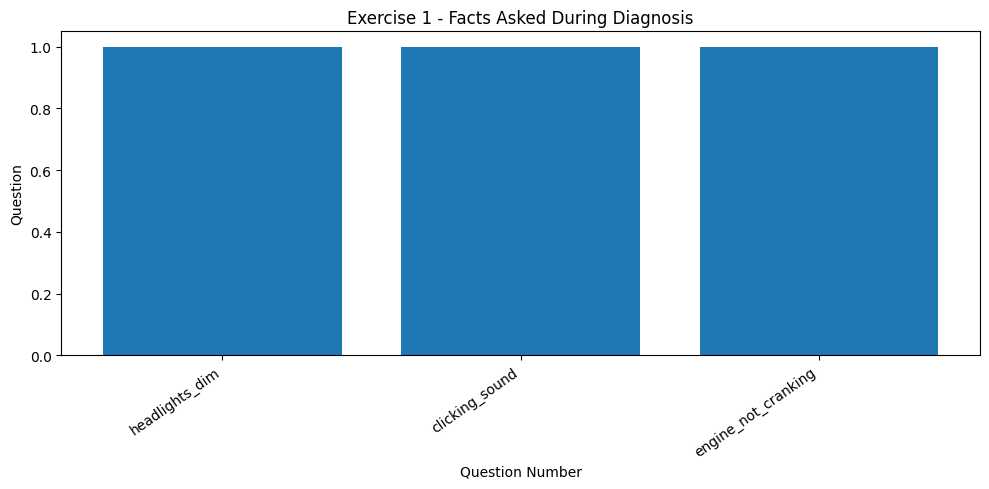

In [9]:
# Exercise 1 - question sequence visualization
if len(exercise1_table) > 0:
    plt.figure(figsize=(10, 5))
    plt.bar(
        range(1, len(exercise1_table) + 1),
        np.ones(len(exercise1_table))
    )
    plt.xticks(
        range(1, len(exercise1_table) + 1),
        exercise1_table["fact"],
        rotation=35,
        ha="right"
    )
    plt.title("Exercise 1 - Facts Asked During Diagnosis")
    plt.xlabel("Question Number")
    plt.ylabel("Question")
    plt.tight_layout()
    plt.show()


### Exercise 1 - Observation

The engine works backward from the hypotheses. When it reaches the starter motor rule, it requests the observations required by that rule. When clicking sound and engine not cranking are confirmed, the starter motor fault is established.


# Exercise 2 - Effect of Hypothesis Order

The same observations are evaluated using two different hypothesis orders. The question sequence is compared to observe the effect of hypothesis ordering.


In [10]:
answers_for_order_test = {
    "headlights_dim": False,
    "engine_not_cranking": True,
    "clicking_sound": True,
    "battery_voltage_low": False,
    "temperature_high": False,
    "coolant_low": False,
    "engine_cranks": False,
    "fuel_available": False,
    "fuel_pump_sound": False,
    "spark_present": False
}

order_a = [
    "battery_fault",
    "starter_motor_fault",
    "fuel_system_fault",
    "ignition_fault",
    "electrical_fault",
    "engine_overheating"
]

order_b = [
    "starter_motor_fault",
    "battery_fault",
    "fuel_system_fault",
    "ignition_fault",
    "electrical_fault",
    "engine_overheating"
]

def run_order(order):
    e = BackwardChainingEngine(
        rules=rules,
        askable_facts=askable_facts,
        scripted_answers=answers_for_order_test
    )
    return e.diagnose(order)

result_a = run_order(order_a)
result_b = run_order(order_b)

questions_a = [q["fact"] for q in result_a["questions"]]
questions_b = [q["fact"] for q in result_b["questions"]]
max_questions = max(len(questions_a), len(questions_b))

order_comparison = pd.DataFrame({
    "Question Number": range(1, max_questions + 1),
    "Order A Questions": questions_a + ["-"] * (max_questions - len(questions_a)),
    "Order B Questions": questions_b + ["-"] * (max_questions - len(questions_b))
})

print("Order A diagnosis:", result_a["fault"])
print("Order B diagnosis:", result_b["fault"])
display(order_comparison)


Order A diagnosis: starter_motor_fault
Order B diagnosis: starter_motor_fault


,Question Number,Order A Questions,Order B Questions
0,1,headlights_dim,clicking_sound
1,2,clicking_sound,engine_not_cranking
2,3,engine_not_cranking,-


,Hypothesis Order,First Hypothesis,Diagnosis,Number of Questions,Question Sequence
0,Order A,battery_fault,starter_motor_fault,3,headlights_dim -> clicking_sound -> engine_not...
1,Order B,starter_motor_fault,starter_motor_fault,2,clicking_sound -> engine_not_cranking


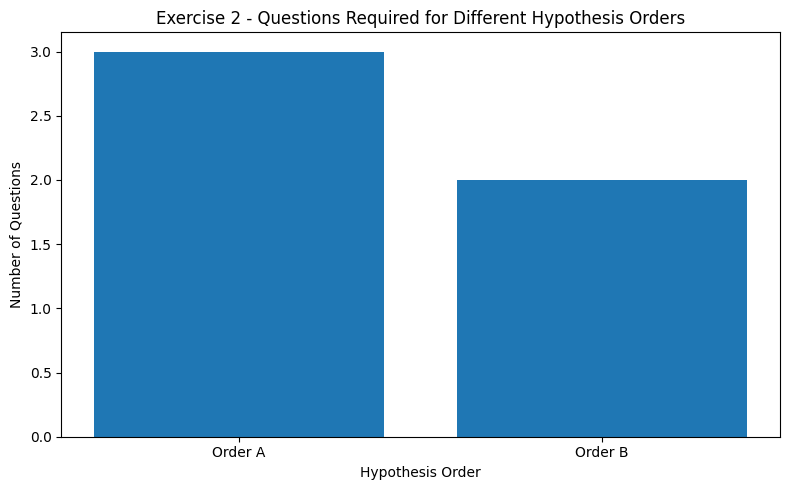

In [11]:
order_summary = pd.DataFrame({
    "Hypothesis Order": ["Order A", "Order B"],
    "First Hypothesis": [order_a[0], order_b[0]],
    "Diagnosis": [result_a["fault"], result_b["fault"]],
    "Number of Questions": [
        len(result_a["questions"]),
        len(result_b["questions"])
    ],
    "Question Sequence": [
        " -> ".join(q["fact"] for q in result_a["questions"]),
        " -> ".join(q["fact"] for q in result_b["questions"])
    ]
})

display(order_summary)

plt.figure(figsize=(8, 5))
plt.bar(
    order_summary["Hypothesis Order"],
    order_summary["Number of Questions"]
)
plt.title("Exercise 2 - Questions Required for Different Hypothesis Orders")
plt.xlabel("Hypothesis Order")
plt.ylabel("Number of Questions")
plt.tight_layout()
plt.show()


### Exercise 2 - Observation

Changing the hypothesis order changes the path followed by the backward chaining engine. A hypothesis placed earlier can be established before later hypotheses are explored, reducing unnecessary questions.


# Exercise 3 - WHY Option

The WHY option explains why a particular fact is being requested. The explanation identifies the rule responsible for the question and the conclusion that the rule is trying to establish.


In [12]:
why_engine = BackwardChainingEngine(
    rules=rules,
    askable_facts=askable_facts,
    scripted_answers={
        "engine_not_cranking": True,
        "clicking_sound": True
    },
    why_mode=True
)

why_result = why_engine.diagnose(["starter_motor_fault"])

why_table = pd.DataFrame(why_result["reasons"])
display(why_table)


,fact,goal,rule,reason
0,clicking_sound,clicking_sound,R2,R2: IF clicking_sound AND engine_not_cranking ...
1,engine_not_cranking,engine_not_cranking,R2,R2: IF clicking_sound AND engine_not_cranking ...


In [13]:
for item in why_result["reasons"]:
    print(f"Question: {item['fact']}")
    print(f"WHY: {item['reason']}")
    print()


Question: clicking_sound
WHY: R2: IF clicking_sound AND engine_not_cranking THEN starter_motor_fault

Question: engine_not_cranking
WHY: R2: IF clicking_sound AND engine_not_cranking THEN starter_motor_fault



### Exercise 3 - Observation

The WHY facility makes the reasoning process explainable. When a question is asked, the system can show which diagnostic rule requires the fact and which fault is being investigated.


# Additional Diagnostic Cases

The engine is tested on multiple fault scenarios to verify the backward chaining implementation.


In [14]:
test_cases = {
    "Starter motor fault": (
        {"engine_not_cranking": True, "clicking_sound": True},
        "starter_motor_fault"
    ),
    "Battery fault": (
        {"headlights_dim": True, "engine_not_cranking": True},
        "battery_fault"
    ),
    "Engine overheating": (
        {"temperature_high": True, "coolant_low": True},
        "engine_overheating"
    ),
    "Electrical fault": (
        {
            "headlights_dim": False,
            "engine_not_cranking": True,
            "clicking_sound": False,
            "battery_voltage_low": True
        },
        "electrical_fault"
    )
}

test_rows = []

for case_name, (answers, expected) in test_cases.items():
    e = BackwardChainingEngine(
        rules=rules,
        askable_facts=askable_facts,
        scripted_answers=answers
    )
    r = e.diagnose(hypotheses)

    test_rows.append({
        "Case": case_name,
        "Expected Fault": expected,
        "Identified Fault": r["fault"],
        "Correct": r["fault"] == expected,
        "Questions": len(r["questions"])
    })

test_results = pd.DataFrame(test_rows)
display(test_results)


,Case,Expected Fault,Identified Fault,Correct,Questions
0,Starter motor fault,starter_motor_fault,starter_motor_fault,True,3
1,Battery fault,battery_fault,battery_fault,True,2
2,Engine overheating,engine_overheating,engine_overheating,True,6
3,Electrical fault,electrical_fault,electrical_fault,True,5


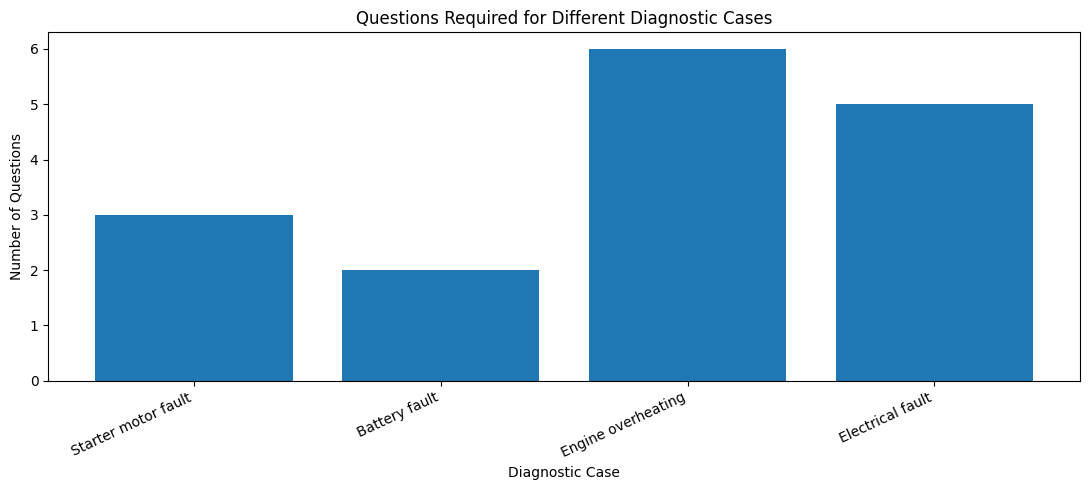

In [15]:
plt.figure(figsize=(11, 5))
plt.bar(test_results["Case"], test_results["Questions"])
plt.title("Questions Required for Different Diagnostic Cases")
plt.xlabel("Diagnostic Case")
plt.ylabel("Number of Questions")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


# Complexity Analysis

Let:

- R be the number of rules.
- C be the maximum number of conditions in a rule.
- D be the maximum depth of recursive reasoning.

For a straightforward rule scan, selecting candidate rules requires O(R) work. Recursive proof of rule conditions depends on the structure and depth of the knowledge base.

For a small diagnostic knowledge base, the practical cost is low. The main advantage of backward chaining is that it focuses reasoning on the current goal and avoids asking unrelated questions.


# Results and Conclusion

## Exercise 1

The starter motor fault was added using clicking sound and engine not cranking. The engine correctly identifies the starter motor fault when both observations are true.

## Exercise 2

Changing the order of hypotheses changes the sequence of questions because backward chaining explores hypotheses in the specified order.

## Exercise 3

The WHY option provides the rule responsible for requesting a fact, making the diagnostic process easier to understand.

## Conclusion

A goal-driven backward chaining engine was implemented for car-fault diagnosis using askable facts. The system works backward from possible faults, requests only the facts needed to establish a hypothesis, stores responses in working memory, and derives the appropriate diagnosis. The experiments demonstrate the effect of hypothesis ordering and the use of a WHY facility for explainable rule-based reasoning.
